In [1]:
import gc
import os
import time
import random
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sys import getsizeof

import tensorflow as tf
print(tf.__version__)

from tensorflow.keras import metrics
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers, callbacks
from tensorflow.keras.models import Sequential, Model

#from tensorflow_large_model_support import LMS

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

2.18.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

dataSourcePath = '/content/drive/MyDrive/Pol_Sl/POL_LABS/SmartIndustry_Lab/dataset_20240526_175526/'
modelsFolderPath = '/content/drive/MyDrive/Pol_Sl/POL_LABS/SmartIndustry_Lab/'

Mounted at /content/drive


In [3]:

modelName = 'Mexh256_CNN_v1'

inputShape = (256, 300, 6)

classes = 4
shuffle_seed = 123
trainSize = 0.8
valSize = 0.1

In [4]:
# Read datset:

datasetPath = dataSourcePath + 'dataset_np.pickle'
lablesPath =  dataSourcePath + 'lables_np.pickle'

with open(datasetPath, 'rb') as f:
  data = pickle.load(f)

with open(lablesPath, 'rb') as f:
  lables = pickle.load(f)

In [5]:
# Shuffle:
print(type(data))

c = list(zip(data, lables))
random.Random(shuffle_seed).shuffle(c)
data, lables = zip(*c)

print(type(data))

# free 'c' from memory
del c
gc.collect()
time.sleep(10)

data = np.array(data)
lables=np.array(lables)

print(data.shape)
print(lables.shape)

<class 'list'>
<class 'tuple'>
(107, 256, 300, 6)
(107,)


85


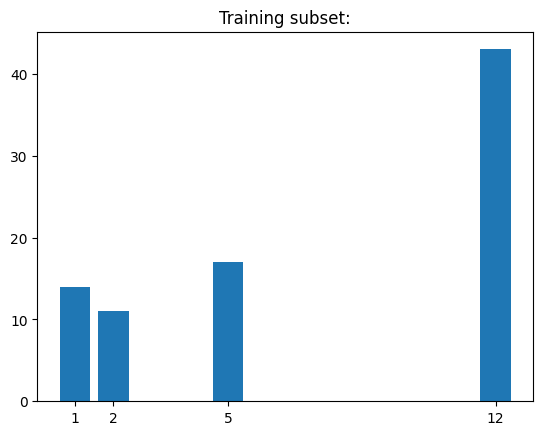

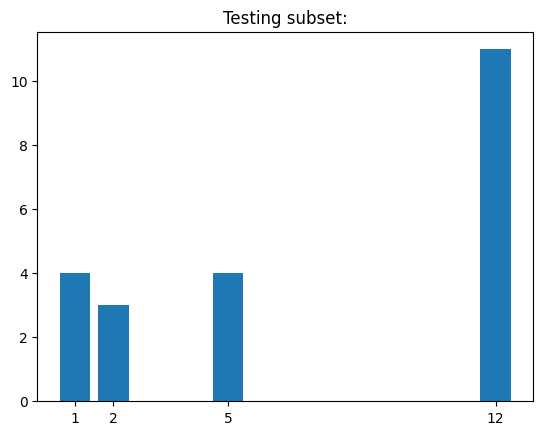

In [6]:
# Plot classes occurrences

bound = int(len(lables)*trainSize)
print(bound)

uniqueTrain, countTrain = np.unique(lables[:bound], return_counts=True)
uniqueTest, countTest = np.unique(lables[bound:], return_counts=True)

# Training histogram
plt.title("Training subset:")
plt.bar(uniqueTrain, height = countTrain)
plt.xticks(uniqueTrain, [str(s) for s in uniqueTrain] )
plt.show()
plt.close()

# Testing  histogram
plt.title("Testing subset:")
plt.bar(uniqueTest, height = countTest)
plt.xticks(uniqueTest, [str(s) for s in uniqueTest] )
plt.show()
plt.close()


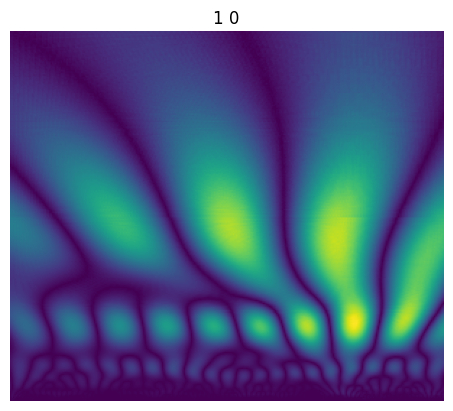

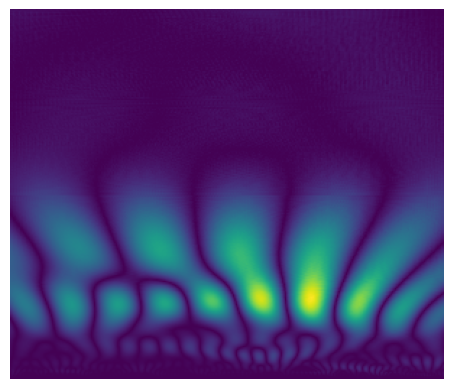

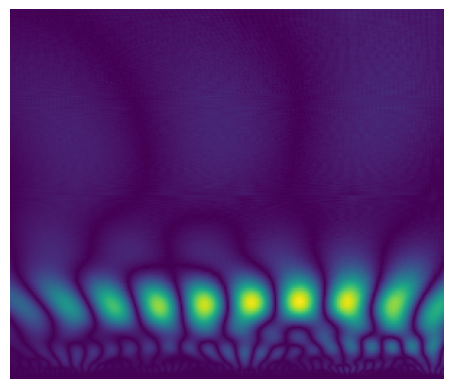

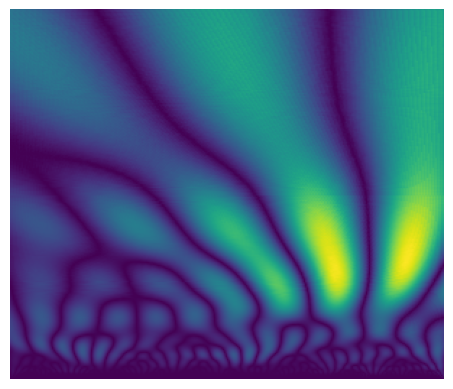

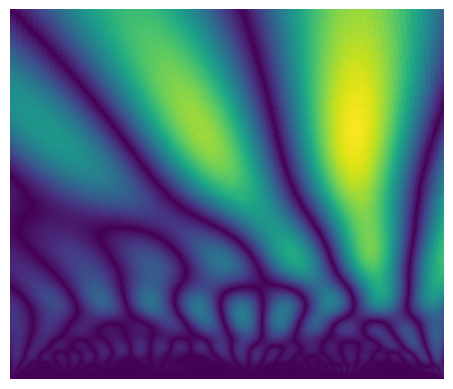

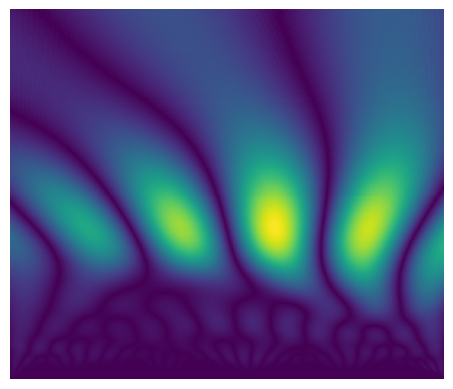

In [7]:
# Plot data:

for i in range(0, 1):
  plt.title(str(lables[i])+ " " + str(i))
  for j in range(0, 6):
    plt.axis("off")
    plt.imshow(data[i, :, :, j])
    plt.show()
    plt.close()
  print()

In [8]:
# Normalize
maxval = data.max().max()
gc.collect()

data = data/maxval
gc.collect()

print(data.shape)

(107, 256, 300, 6)


In [9]:
# To one hot encoding:

lables = pd.get_dummies(lables)
print(lables[:5])

print(type(lables))
print(lables.shape)
print(type(data))
print(data.shape)

      1      2      5      12
0   True  False  False  False
1  False  False  False   True
2  False  False  False   True
3   True  False  False  False
4  False   True  False  False
<class 'pandas.core.frame.DataFrame'>
(107, 4)
<class 'numpy.ndarray'>
(107, 256, 300, 6)


In [10]:
modelPath = modelsFolderPath + modelName + '/'

model = Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=inputShape))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(classes, activation='softmax'))

optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)

model.compile(optimizer = optimizer , loss = 'categorical_crossentropy' , metrics = ['accuracy', metrics.Precision(), metrics.Recall(), metrics.AUC()])
model.summary()

ReduceLROnPlateau_callback = callbacks.ReduceLROnPlateau(
    monitor='val_accuracy',
    patience = 20,
    verbose=1,
    factor=0.3,
    min_lr=0.0000001)

# ModelCheckpoint_callback = callbacks.ModelCheckpoint(
#     modelPath + 'mdl_wts.hdf5',
#     save_best_only=True,
#     monitor='val_accuracy',
#     mode='max')

ModelCheckpoint_callback = callbacks.ModelCheckpoint(
    modelPath + 'mdl_wts.keras',
    save_best_only=True,
    save_weights_only=False,  # Можна не писати, бо False за замовчуванням
    monitor='val_loss',
    mode='min'
)

EarlyStopping_callback = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    start_from_epoch = 20,
    verbose=0,
    mode='min')



/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 298, 32)   │         1,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 149, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 147, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 73, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 71, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 35, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 33, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 59136)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │     1,892,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,986,628 (7.58 MB)

 Trainable params: 1,986,628 (7.58 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Split to train and test subsets:
print(bound)

X_train = data[0:bound]
Y_train = lables[0:bound]
X_test =  data[bound:]
Y_test =  lables[bound:]

print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

85
(85, 256, 300, 6)
(22, 256, 300, 6)
(85, 4)
(22, 4)


In [12]:
del data
del lables
gc.collect()

13

In [13]:
epochs = 70
batch_size=16

hist = model.fit(
    x=X_train,
    y=Y_train,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    #callbacks=[ReduceLROnPlateau_callback, ModelCheckpoint_callback, EarlyStopping_callback],
    callbacks=[ReduceLROnPlateau_callback, ModelCheckpoint_callback],
    validation_split=valSize,
    shuffle=True
)

Epoch 1/70
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.2999 - auc: 0.5332 - loss: 1.3756 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.5556 - val_auc: 0.6872 - val_loss: 1.2320 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/70
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - accuracy: 0.5200 - auc: 0.7374 - loss: 1.2119 - precision: 0.5314 - recall: 0.1562 - val_accuracy: 0.5556 - val_auc: 0.7387 - val_loss: 1.1652 - val_precision: 0.5556 - val_recall: 0.5556 - learning_rate: 1.0000e-04
Epoch 3/70
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.5356 - auc: 0.8251 - loss: 1.0732 - precision: 0.6965 - recall: 0.4980 - val_accuracy: 0.5556 - val_auc: 0.7654 - val_loss: 1.1610 - val_precision: 1.0000 - val_recall: 0.3333 - learning_rate: 1.0000e-04
Epoch 4/70
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.5131 - auc: 0.8449 - loss: 1.0507 - precision: 0.9363 - recall: 0.2607 - val_accuracy: 0.5556 - val_auc: 0.7140 - val_lo

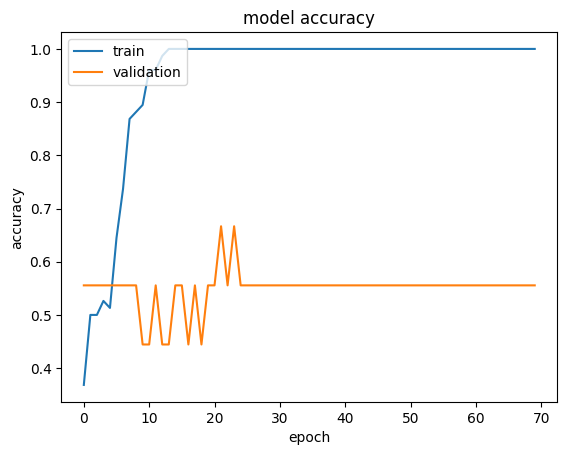

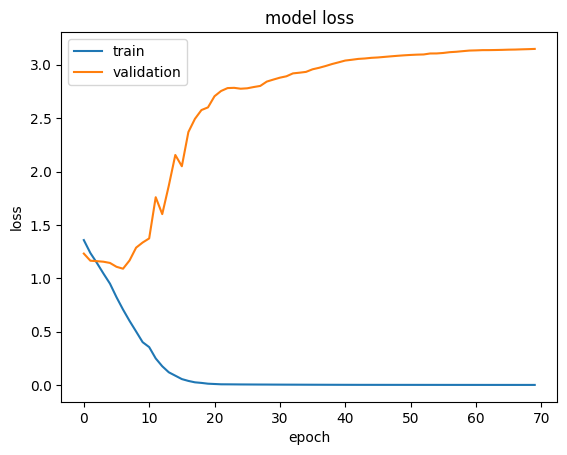

In [14]:
# summarize history for accuracy

plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()
plt.close()

# summarize history for loss

plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()
plt.close()

In [15]:
# Save model and history

# model.save(modelPath + modelName)
model.save(modelPath + modelName + ".keras")

with open(modelPath+'history_dict.pickle', 'wb') as f:
  pickle.dump(hist.history, f, protocol=4)

In [16]:
# Load last model

savedModelPath = modelPath + modelName
# loaded_model = tf.keras.models.load_model(savedModelPath)
loaded_model = tf.keras.models.load_model(modelPath + modelName + ".keras")

In [17]:
# Evaluate the last model

results = loaded_model.evaluate(X_test, Y_test, verbose=1 )
print(loaded_model.metrics_names)
print("evaluation results: ", results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5455 - auc: 0.8092 - loss: 1.7601 - precision: 0.5714 - recall: 0.5455
['loss', 'compile_metrics']
evaluation results:  [1.760068416595459, 0.5454545617103577, 0.5714285969734192, 0.5454545617103577, 0.8092286586761475]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step


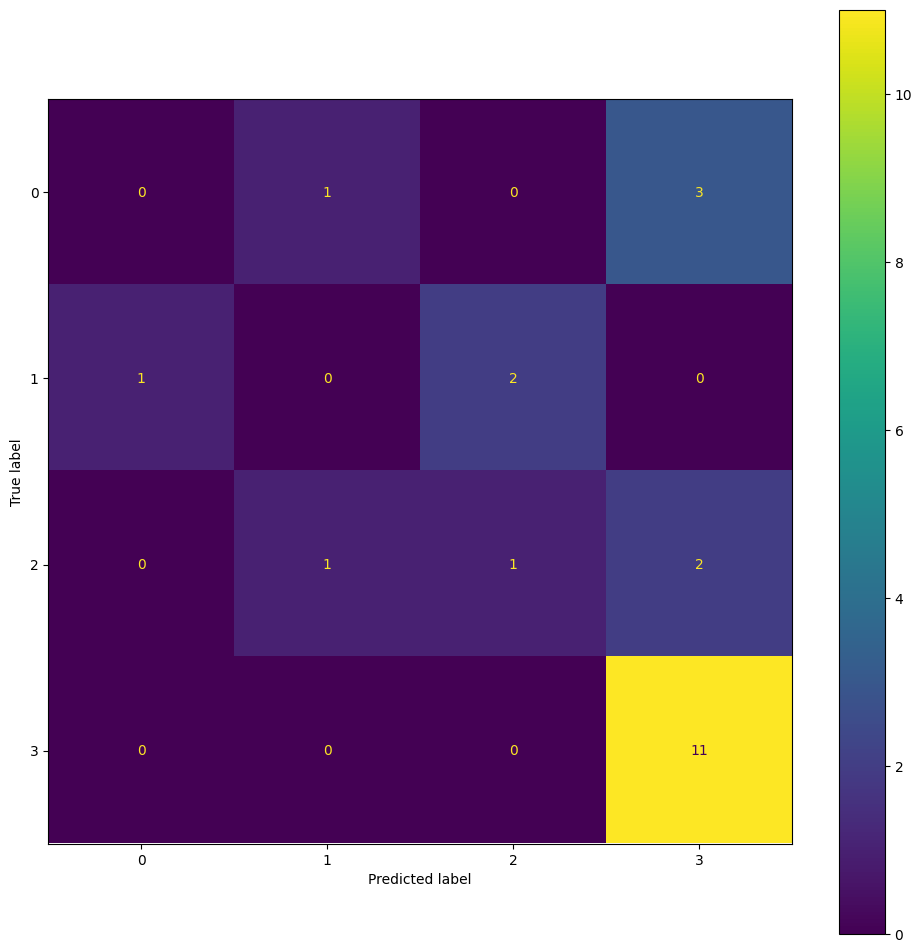

In [18]:
Y_pred = loaded_model.predict(X_test)
Y_pred_argmax = np.argmax(Y_pred, axis=1)
Y_test_argmax = np.argmax(Y_test.to_numpy(), axis=1)

matrix = confusion_matrix(Y_test_argmax, Y_pred_argmax)
disp = ConfusionMatrixDisplay(matrix)
fig, ax = plt.subplots(figsize=(12,12))
disp.plot(ax=ax)
plt.show()
plt.close()

In [20]:
# Load best model

weightsPath = modelPath + modelName + ".keras"
loaded_model.load_weights(weightsPath)

In [21]:
# Evaluate the best model:

results = loaded_model.evaluate(X_test, Y_test, verbose=1 )
print(loaded_model.metrics_names)
print("evaluation results: ", results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5455 - auc: 0.8092 - loss: 1.7601 - precision: 0.5714 - recall: 0.5455
['loss', 'compile_metrics']
evaluation results:  [1.760068416595459, 0.5454545617103577, 0.5714285969734192, 0.5454545617103577, 0.8092286586761475]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


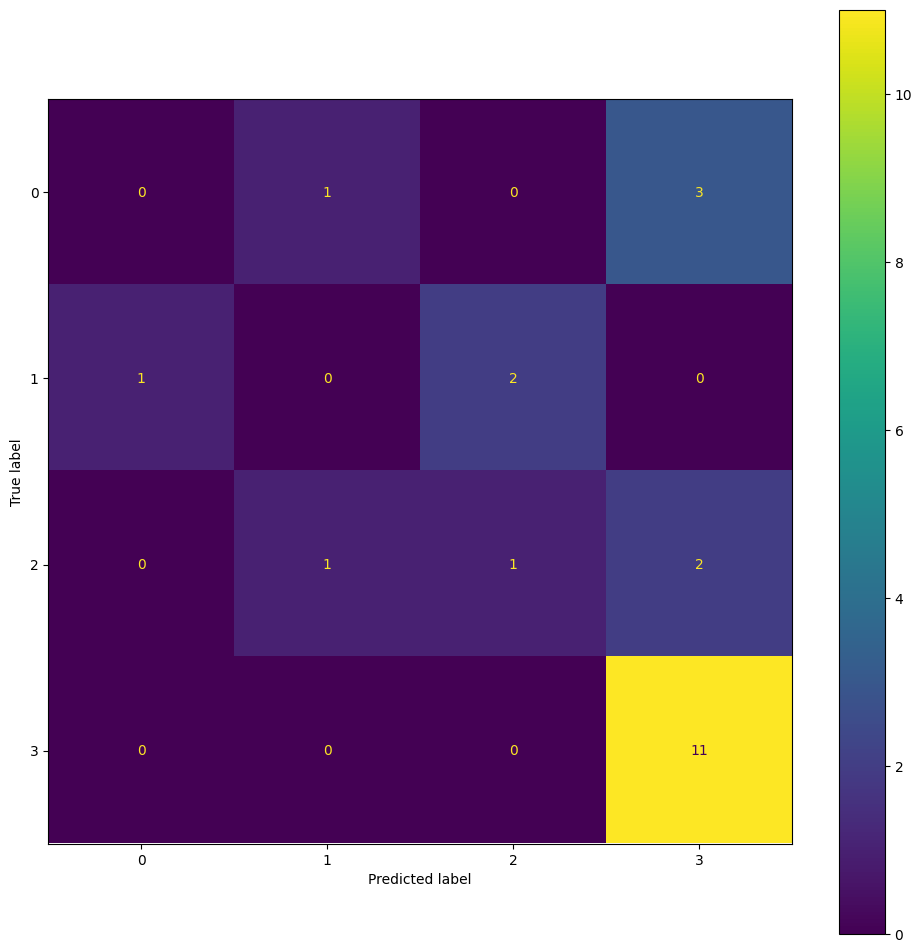

In [22]:
Y_pred = loaded_model.predict(X_test)
Y_pred_argmax = np.argmax(Y_pred, axis=1)
Y_test_argmax = np.argmax(Y_test.to_numpy(), axis=1)

matrix = confusion_matrix(Y_test_argmax, Y_pred_argmax)
disp = ConfusionMatrixDisplay(matrix)
fig, ax = plt.subplots(figsize=(12,12))
disp.plot(ax=ax)
plt.show()
plt.close()

In [23]:
Y_test_argmax

array([1, 2, 3, 3, 0, 3, 0, 3, 3, 0, 1, 3, 2, 2, 2, 1, 3, 3, 3, 3, 3, 0])

In [24]:
Y_pred_argmax

array([2, 1, 3, 3, 3, 3, 1, 3, 3, 3, 0, 3, 2, 3, 3, 2, 3, 3, 3, 3, 3, 3])